# Fit a microscope from MAGICAL images

We will:

1. Make MAGICAL images with a simulated microscope.
2. Measure their scale, rotation and blur.
3. Fit a second microscope, starting from guesses.
4. Compare the fitted microscope with the one that made the images.

Use **40,000× and 150,000×**. At each magnification, take one reference image and wobble IL1, IL2, IL3 and PL1 by ±2.5%, one lens at a time. That gives **18 images, all used in the fit**.

In [1]:
from pathlib import Path
import os
import sys

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import jax
jax.config.update("jax_enable_x64", True)

project_folder = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "src/temgym_core").is_dir()
)
example_folder = project_folder / "examples/microscope_models"
sys.path.insert(0, str(project_folder / "src"))
sys.path.insert(0, str(example_folder))

from projector_notebook_helpers import (
    simulate_experiment, measure_images, fit_microscope,
    load_position_priors, load_simulated_truth,
    show_images, show_measurements, show_position_priors,
    show_image_fit, compare_models,
)

%matplotlib inline

## The model

We use five finite solenoid lenses. Their positions, lengths and strengths are unknown. We also fit the beam's convergence, angular spread and the sample's rotation: **19 parameters in total**.

In our usual ray coordinates,

$$
\begin{pmatrix}x_d\\y_d\\\theta_{x,d}\\\theta_{y,d}\\1\end{pmatrix}
=
\begin{pmatrix}
A_{xx}&A_{xy}&B_{xx}&B_{xy}&t_x\\
A_{yx}&A_{yy}&B_{yx}&B_{yy}&t_y\\
C_{xx}&C_{xy}&D_{xx}&D_{xy}&u_x\\
C_{yx}&C_{yy}&D_{yx}&D_{yy}&u_y\\
0&0&0&0&1
\end{pmatrix}
\begin{pmatrix}x_s\\y_s\\\theta_{x,s}\\\theta_{y,s}\\1\end{pmatrix}.
$$

$A$ describes magnification and rotation. $B$ describes how the starting angle changes the image position. At perfect focus, $B=0$. The image does not directly measure the outgoing angles described by $C$ and $D$.

We assume aligned lenses. Small image shifts are fitted separately for each image.

## 1. Make the images

**Supply:** two magnifications, the wobble size, voltage and detector settings.

**Get back:** `experiment`, containing the images, lens commands and known specimen template. The true microscope parameters are saved separately for the final comparison.

The sample is our synthetic MAGICAL target, with 13 nm Si and 10 nm SiGe layers. This example uses its known intensity pattern, smoothed by 2 nm Gaussian components. It includes counting noise and read noise, but no coherent phase contrast. We keep the illumination profile fixed and use the same sample region throughout.

In [2]:
experiment = simulate_experiment(
    magnifications=[40_000, 150_000],
    wobble_fraction=0.025,              # ±2.5% around each reference setting
    voltage_v=200_000,
    detector_pixel_size_m=110e-6,       # 110 micrometres per pixel
    detector_shape=(128, 128),
    output_directory=project_folder / "examples/generated/simple_magical_fit",
    random_seed=7391,
)

print("Number of images:", len(experiment.images))
print("Lens-command columns: IL1, IL2, IL3, PL1")

Number of images: 18
Lens-command columns: IL1, IL2, IL3, PL1


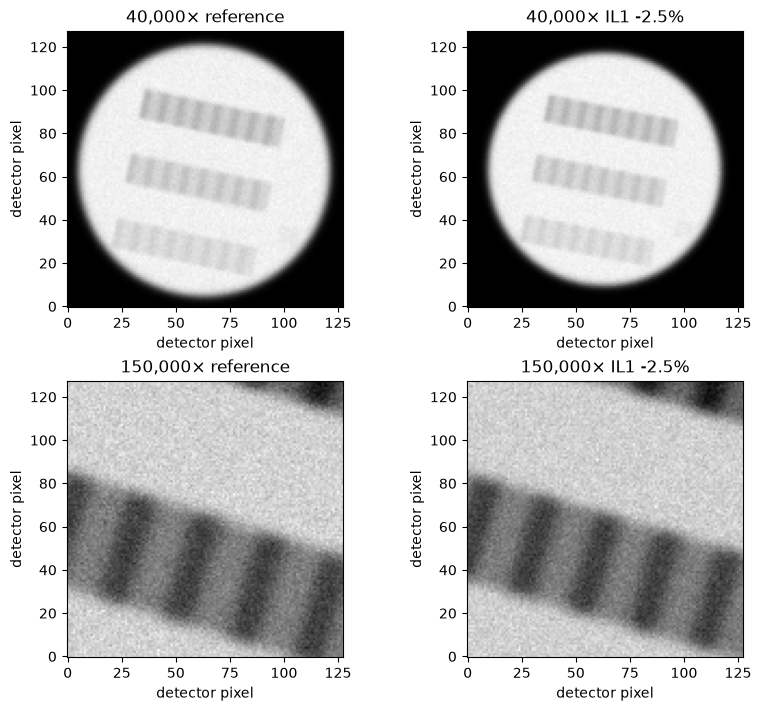

In [3]:
# Show a reference and one wobble image at each magnification.
show_images(
    images=experiment.images,
    image_labels=experiment.image_labels,
    indices=[0, 1, 9, 10],
)

## 2. Measure the images

**Supply:** the images, known sample pattern and detector settings. The magnification labels give the image search a starting point.

**Get back:** `measurements`, with one scale, rotation, blur width and uncertainty per image. Image position, brightness and background are also fitted so they do not have to be known.

This step knows nothing about the lens positions or strengths.

In [4]:
measurements = measure_images(
    images=experiment.images,
    nominal_magnifications=experiment.nominal_magnifications,
    specimen_template=experiment.specimen_template,
    specimen_and_detector=experiment.specimen_and_detector,
)

# These are the measured quantities that the microscope must explain.
show_measurements(
    measurements=measurements,
    image_labels=experiment.image_labels,
    indices=[0, 1, 9, 10],
)

Image,Measured scale,Rotation (degrees),Blur width (pixels)
"40,000× reference","39,997.7",-12.023,0.731
"40,000× IL1 -2.5%","36,997.1",-11.253,0.671
"150,000× reference","149,946.0",-17.086,2.691
"150,000× IL1 -2.5%","138,761.9",-16.300,2.540


## 3. Supply a starting guess and position bounds

All positions below are measured from the specimen. These are guesses, not the generating values.

The strength model uses an integrated solenoid strength `q`. For IL1–PL1, its magnitude is `gain × lens command`; each lens keeps its chosen polarity. The objective command stays fixed, but its strength is fitted.

In [5]:
starting_guess = {
    "lens_positions_mm": {
        "Objective": 2.75, "IL1": 196, "IL2": 281, "IL3": 336, "PL1": 399.6,
    },
    "lens_lengths_mm": {
        "Objective": 0.5, "IL1": 6, "IL2": 4, "IL3": 6, "PL1": 1.2,
    },
    "detector_position_mm": 740.2,
    "objective_strength": -0.40,
    "excitation_gains": {"IL1": 0.50, "IL2": 0.60, "IL3": 0.50, "PL1": 0.70},
    "beam_curvature_per_m": 0.0,       # start with no convergence or divergence
    "angular_spread_mrad": 1.2,
    "sample_rotation_deg": 0.0,
}

The position priors give a preferred position, an uncertainty and a hard allowed range. They are rough engineering estimates based on our current layout. The fit can move the lenses within these ranges.

The [editable prior file](projector_position_priors.json) also bounds lens lengths. These priors and a preference for the starting values help choose between microscopes that make similar images.

In [6]:
position_priors = load_position_priors(
    path=example_folder / "projector_position_priors.json",
)

show_position_priors(position_priors)

Element,Preferred position (mm),Uncertainty (mm),Allowed range (mm)
Objective,3.0,1.0,1.0 to 6.0
IL1,210.0,20.0,170.0 to 250.0
IL2,290.0,15.0,265.0 to 315.0
IL3,355.0,15.0,325.0 to 385.0
PL1,425.0,20.0,395.0 to 475.0
Detector,740.0,50.0,640.0 to 840.0


## 4. Fit the microscope

**Supply:** the recorded lens commands, image measurements, known specimen/detector values, starting guess and priors.

**Get back:** `fit_result.model`, containing fitted values with the **same names and units as `starting_guess`**. The result also contains the predicted image measurements and an error measured in units of the measurement noise.

The fit uses all 18 images. It keeps their lens commands fixed and does not read the true microscope parameters.

In [7]:
fit_result = fit_microscope(
    lens_controls=experiment.lens_controls,
    image_measurements=measurements,
    specimen_and_detector=experiment.specimen_and_detector,
    starting_guess=starting_guess,
    position_priors=position_priors,
)

fitted_model = fit_result.model
print("Fitted lens positions:")
for lens_name, position_mm in fitted_model["lens_positions_mm"].items():
    print(f"  {lens_name:10s} {position_mm:8.3f} mm")
print("Fit error in noise units:", round(fit_result.error_in_noise_units, 3))

Fitted lens positions:
  Objective     2.864 mm
  IL1         215.533 mm
  IL2         285.916 mm
  IL3         354.852 mm
  PL1         428.882 mm
Fit error in noise units: 0.872


## 5. Check the result

Compare the original images with images made using the fitted microscope. The lens fit predicts scale, rotation and blur; image shifts, brightness and background come from the image-analysis step.

An error near one noise unit means that the remaining differences are roughly the size of the estimated measurement noise.

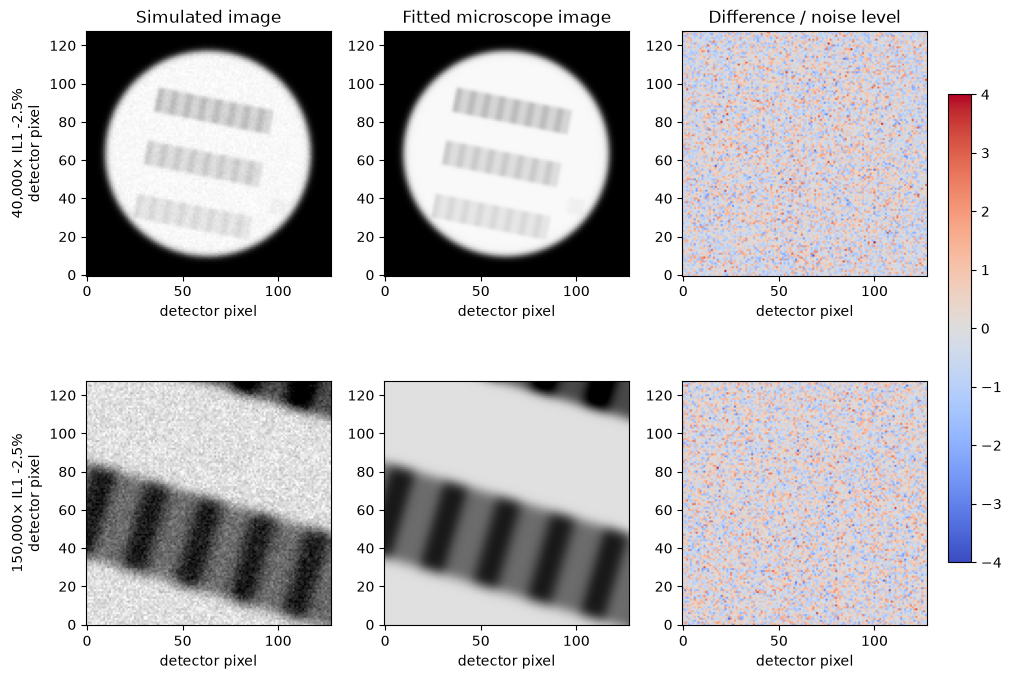

In [8]:
show_image_fit(
    experiment=experiment,
    measurements=measurements,
    fit_result=fit_result,
    indices=[1, 10],                  # one wobble at each magnification
)

Finally, open the true parameters and compare positions and lengths. This tells us whether fitting the images also recovered the microscope geometry.

In [9]:
true_model = load_simulated_truth(
    output_directory=experiment.output_directory,
)

compare_models(
    true_model=true_model,
    fitted_model=fitted_model,
)

Element,True z (mm),Fitted z (mm),Position error (mm),True length (mm),Fitted length (mm)
Objective,2.300,2.864,+0.564,0.400,0.507
IL1,213.524,215.533,+2.009,5.000,4.833
IL2,290.480,285.916,-4.564,5.000,4.847
IL3,352.980,354.852,+1.872,5.000,5.917
PL1,407.983,428.882,+20.898,1.000,0.968
Detector,718.750,734.480,+15.730,—,—


A close image match does not guarantee the correct geometry: different lens and beam parameters can make the same images. The position priors help, so the recovered positions depend on both the images and those assumptions.

The image-analysis, fitting and plotting code is in [projector_notebook_helpers.py](projector_notebook_helpers.py).